# 11. ODEs IV: Nonlinear oscillations

In the previous chapters, we studied numerical methods for solving initial value problems (IVPs) associated with **linear** ordinary differential equations. This included some lesser-known, specialized methods to deal with oscillatory solutions.
In this chapter, we'll look at the (limited) toolbox for solving **nonlinear** oscillatory ODEs, with a focus on **finding periodic orbits/solutions**, rather than following one trajectory for a prescribed length of time. The frequency/period of the orbits we seek are unknown a priori -- finding them is part of the numerical solution.

We'll first discuss how to characterize the stability of a periodic orbit, and why simply running an ODE solver is not a reliable method for finding one. Then we'll introduce the **Lindstedt--Poincaré method**, an analytic perturbation method for finding periodic orbit solution on which we'll build a numerical, iterative algorithm. 

```{admonition} Additional resource
:class: warning
Divakar Viswanath (2001), [*The Lindstedt--Poincaré Technique as an Algorithm for Computing Periodic Orbits*](https://public.websites.umich.edu/divakar/4-Viswanath2001-LindstedtPoincare.pdf), *SIAM Review*, **43**(3), 478--495. The notation for the numerical iteration below follows Section 2 of this paper.
```


## 11.1 Periodic orbits and their stability

Consider an autonomous system of nonlinear ODEs

\begin{align}
\dot{x}(t) &= f(x(t)), \qquad x(t)\in\mathbb{R}^d,
\end{align}

where a dot denotes differentiation with respect to $t$. Assume that $f$ is at least twice continuously differentiable (though, in many applications, it will be analytic). We would like to calculate a *periodic orbit*: a nonconstant solution $x(t)$ for which

$$x(t+T)=x(t)\qquad \forall t,$$

for some period $T>0$. Its frequency is $\omega=2\pi/T$. Both the orbit $x(t)$ and $T$ are unknown.

To see why simple Runge--Kutta methods don't always work in the above example, we have to analyze this ODE a bit further.

### 11.1.1 Linearization

To see how solutions of the nonlinear ODE behave, it is common to perform stability analysis by linearization as follows. Suppose $x(t)$ is a periodic orbit. Perturb it by a small displacement $\delta x(t)$ and expand the right-hand-side in a Taylor series around $x(t)$ to get

\begin{align}
\frac{d}{dt}(x+\delta x)
&=f(x+\delta x)\\
&=f(x)+\left.\frac{\partial f}{\partial x}\right|_{x=x(t)}\delta x+\mathcal{O}(\|\delta x\|^2).
\end{align}

Subtracting $\dot{x}=f(x)$, denoting $\delta x(t) = y(t)$, and neglecting quadratic terms gives the *variational equation*

```{math}
:label: ch11-variational
\dot y(t)=A(t)y(t),\qquad
A(t)=\left.\frac{\partial f}{\partial x}\right|_{x=x(t)}.
```

Here $A(t+T)=A(t)$ because $x(t)$ is periodic. Let $Y(t)\in\mathbb{R}^{d\times d}$ be the fundamental matrix solution, defined by

$$\dot Y(t)=A(t)Y(t),\qquad Y(0)=I,$$

where $I$ is a $d \times d$ identity matrix. Each column of $Y(t)$ is a solution of the variational equation that starts from a different initial condition, with one component of $y(0)$ being 1, the rest 0. Due to the linearity of the variational equation, we can linearly combine these $d$ individual solutions to match any initial condition, meaning $y(t)=Y(t)y(0)$. The matrix

```{math}
:label: ch11-monodromy
M=Y(T)
```

is called the **monodromy matrix**. It maps an infinitesimal perturbation through one period: $y(T)=My(0)$. Its eigenvalues $\lambda_i$ are the *Floquet multipliers* (the nontrivial ones are often called *characteristic multipliers*).

There is always a multiplier $\lambda=1$: the perturbation $y(t)=\dot{x}(t)$ solves the variational equation, and $\dot{x}(T)=\dot{x}(0)$. It corresponds to starting at a slightly different point **along the same orbit**.


### 11.1.2 Characteristic multipliers

The multipliers other than the compulsory $1$ determine the linear behavior *transverse* to the orbit:

- If all transverse multipliers satisfy $|\lambda_i|<1$, the orbit is attracting (asymptotically stable).
- If all transverse multipliers satisfy $|\lambda_i|>1$, the orbit is repelling in forward time.
- If some are inside and some outside the unit circle, the orbit is a saddle.
- If additional multipliers lie on the unit circle, the linearization alone may not decide the nonlinear stability.

For example, if the dominant contracting multiplier has magnitude $0.8$ and the initial displacement in that direction is $10^{-1}$, its linearized size after $n$ periods is approximately $10^{-1}(0.8)^n$. This is **geometric (linear) convergence** to the orbit. In contrast, the numerical method described here will have a **quadratically convergent** iteration, meaning it would produce errors $10^{-1},10^{-2},10^{-4},10^{-8},\ldots$ (when starting from an initial guess that is suitably close to the solution). 

```{admonition} Question
Why might integrating forward for many periods fail to find a saddle-type periodic orbit, even if the initial condition is very close to it?
```


## 11.2 Why not just use an IVP solver?

The most obvious idea for solving an ODE like this would be to pick an initial condition near the desired orbit, integrate $\dot{x}=f(x)$ forward using a Runge--Kutta or multistep method, and hope that the trajectory converges (to the desired orbit). This can work for an attracting orbit, but it fails for a repelling orbit and, generally, for a saddle orbit. Even when it works, convergence to the orbit is usually only geometric, as predicted by the Floquet multipliers.

There are algorithms that instead turn periodic-orbit calculation into a nonlinear system. As an example, write $\phi_s:\mathbb{R}^d\to\mathbb{R}^d$ for the flow map: $\phi_s(a)$ is the solution obtained by integrating the ODE for time $s$, starting at $a$. If $x_1,\ldots,x_{N-1}$ are successive points on a periodic orbit at times $t_1<\cdots<t_N$, with $x_N=x_1$, then

\begin{align}
\phi_{t_2-t_1}(x_1)&=x_2,\\
\phi_{t_3-t_2}(x_2)&=x_3,\\
&\ \vdots\\
\phi_{t_N-t_{N-1}}(x_{N-1})&=x_1.
\end{align}

These are *multiple-shooting* equations. Their unknowns include the points and segment lengths, and $T=t_N-t_1$. With appropriate additional constraints they can be solved by Newton's method. The software package AUTO implements an approach based on the above strategy.

The calculation of periodic orbits, much like finding a root of $f(x)=0$, generally requires a **sufficiently good initial guess**. The main advantage of Newton-type algorithms is that, near a regular solution, their convergence can be quadratic instead of geometric.

In what follows, we'll combine three ideas: the Lindstedt--Poincaré technique from perturbation theory, Newton's method, and Fourier interpolation.


## 11.3 The Lindstedt--Poincaré technique

### 11.3.1 Why a regular perturbation expansion fails

Consider the *Duffing oscillator*

```{math}
:label: ch11-duffing
\ddot{x}+x+\varepsilon x^3=0,\qquad x(0)=1,\qquad \dot{x}(0)=0,
```

with $0<\varepsilon\ll 1$. At $\varepsilon=0$, the ODE is linear (a simple harmonic oscillator), with a frequency of $\omega_0 = 1$ and solution $x_0(t)=\cos t$. Let's try a regular power series to represent the solution, starting from an initial guess $x_0(t)$, and adding successively smaller corrections,

$$x(t)=x_0(t)+\varepsilon x_1(t)+\varepsilon^2x_2(t)+\cdots.$$

Substitute it into the ODE and equate powers of $\varepsilon$. At orders $\varepsilon^0$ and $\varepsilon^1$, respectively, we obtain

\begin{align}
\ddot{x}_0+x_0&=0,\\
\ddot{x}_1+x_1&=-x_0^3.
\end{align}

A solution to the $\varepsilon^0$-order equation that satisfies the initial conditions is $x_0(t) = \cos(t)$, which turns the second ($\varepsilon^1$) equation into

$$ \ddot{x}_1+x_1=-\frac34\cos t-\frac14\cos 3t.$$

For the $x_1$ (and all subsequent) correction to satisfy the initial conditions, we need to set $x_1(0)=\dot{x}_1(0)=0$. Like the ODE for $x_1(t)$, all subsequent ODEs for the $x_i(t)$-s will look like simple harmonic oscillators, with a forcing term (inhomogeneous right-hand-side) determined by the previous correction(s). Solving the ODE for $x_1(t)$ gives

```{math}
:label: ch11-secular
x_1(t)=\frac{\cos 3t-\cos t}{32}-\frac38t\sin t.
```

The term $t\sin t$ grows in amplitude with $t$. It is called a **secular term**, and it makes the perturbation approximation invalid when $\varepsilon t$ is no longer small. It is unphysical for the true solution of the oscillator to grow without bounds, as it doesn't conserve energy (which should be conserved for the Duffing oscillator). It is also clearly not a periodic orbit. The core of the problem is that we expanded around an oscillator with the *wrong frequency*, i.e. we must allow for the frequency of the orbit/solution we seek to be slightly different from our initial guess, $\omega_0$.


### 11.3.2 Analytic Lindstedt--Poincaré

The Lindstedt--Poincaré idea is to allow the frequency to change by introducing the *strained time* (or rescaled time)

$$\tau=\omega t,\qquad \omega=\omega_0+\varepsilon\omega_1+\varepsilon^2\omega_2+\ldots,\qquad \omega_0=1.$$

Now write $x(\tau)=x_0(\tau)+\varepsilon x_1(\tau)+\ldots$. In the variable $\tau$, the original differential equation becomes

$$\omega^2\frac{d^2x}{d\tau^2}+x+\varepsilon x^3=0.$$

At zeroth order in $\varepsilon$ we again have $x_0(\tau)=\cos\tau$. At first order,

\begin{align}
x_1''+x_1
&=-2\omega_1x_0''-x_0^3\\
&=\left(2\omega_1-\frac34\right)\cos\tau-\frac14\cos3\tau.
\end{align}

This has the (parametric) solution

$$
x_1 = \frac{1}{32}(\cos 3\tau - \cos \tau) + (\omega_1 - \frac{3}{8})\tau \sin \tau.
$$

It is clear that with the choice $\omega_1 = \frac{3}{8}$, we can get rid of the problematic secular term. Then the frequency of the first-order accurate approximation of the orbit we seek is

```{math}
:label: ch11-freq-first
\omega=1+\frac38\varepsilon+\mathcal{O}(\varepsilon^2),
```

And the first-order accurate estimate for the solution is

$$x(t)\approx \cos(\omega t)+\frac{\varepsilon}{32}\left[\cos(3\omega t)-\cos(\omega t)\right],\qquad
\omega\approx1+\frac38\varepsilon.$$

In a nutshell, allowing the frequency of the orbit we seek to be different than the inital guess has introduced a new unknown ($\omega_1$), whose value we fixed by requiring the solution $x_0 + \varepsilon x_1$ to be periodic with a frequency $\omega = \omega_0 + \varepsilon \omega_1$. This necessarily forces the secular terms to be zero and prevents the solution from growing without bounds. At each iteration of this analytic version of the Poincaré--Lindstedt method, a new pair of unknowns is introduced ($x_i$ and $\omega_i$), and a new pair of constraints come from (1) satisfying the ODE, and (2) setting a secular term to zero.

Below we compare the long-time behavior of the approximation for the solution of the Duffing equation with $\varepsilon = 0.1$ resulting from a regular perturbation expansion, and the Lindstedt--Poincaré.

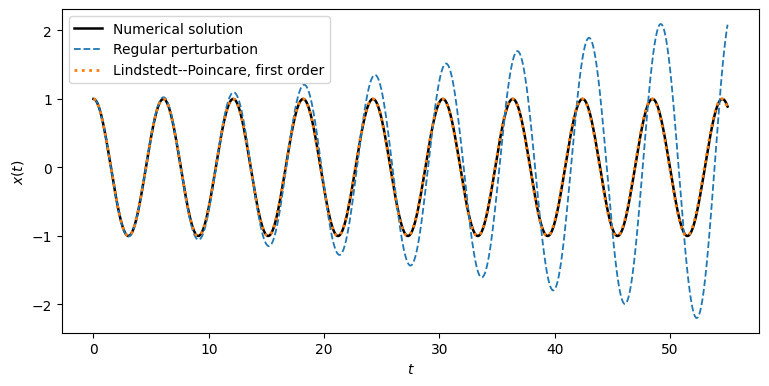

In [7]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.integrate as si

eps = 0.1

def duffing_rhs(t, state, epsilon=eps):
    q, p = state
    return np.array([p, -q - epsilon*q**3])

t = np.linspace(0.0, 55.0, 1600)
sol = si.solve_ivp(duffing_rhs, (t[0],t[-1]), [1.,0.],
                   t_eval=t, method='DOP853', rtol=2e-12, atol=2e-13)
q_true = sol.y[0]
q_regular = np.cos(t) + eps*((np.cos(3*t)-np.cos(t))/32 - 3*t*np.sin(t)/8)
tau = (1+3*eps/8)*t
q_lindstedt = np.cos(tau) + eps*(np.cos(3*tau)-np.cos(tau))/32

fig, ax = plt.subplots(figsize=(9,4.2))
ax.plot(t, q_true, color='black', lw=1.8, label='Numerical solution')
ax.plot(t, q_regular, ls='--', lw=1.3, label='Regular perturbation')
ax.plot(t, q_lindstedt, ls=':', lw=2.0, label='Lindstedt--Poincare, first order')
ax.set(xlabel='$t$', ylabel='$x(t)$')
ax.legend()
plt.show()


## 11.4 Numerical Lindstedt--Poincaré

The perturbative derivation above assumes that $\varepsilon$ is small. Viswanath's (the author of the paper listed at the top) observation is that we can instead linearize the ODE about an approximate periodic orbit and solve for a correction, without discarding terms in the Jacobian just because they contain $\varepsilon$. This gives an iterative numerical algorithm that converges more quickly than the analytic Lindstedt--Poincaré, and is purely numerical (i.e. requires no symbolic algebra). The paper also proposes to represent the initial guess, $x_0$ and all other functions in terms of a truncated Fourier series, which by construction ensures that all solutions will be periodic. 

### 11.4.1 The Duffing equation in Hamiltonian form

Following the paper, let us introduce the generalized poisition, $q=x$, and momentum $p=\dot{q}$. The Duffing equation becomes

$$\dot{q}=p,\qquad \dot{p}=-q-\varepsilon q^3.$$

The associated Hamiltonian (a quantity expressing the total energy in the system) is

```{math}
:label: ch11-energy
H(q,p)=\frac{p^2}{2}+\frac{q^2}{2}+\frac{\varepsilon q^4}{4}.
```

The Hamiltoninan is a conserved quantity in this particular system, and may be used to derive the equation(s) of motion as $\dot q=\partial H/\partial p$ and $\dot p=-\partial H/\partial q$. You can check for yourself that (1) these Hamiltonian equations of motion agree with the original ODE, and (2) that the total derivative of the Hamiltonian, $dH/dt=0$, i.e. the Hamiltonian is conserved. For $\varepsilon>0$, this means that the solutions of the ODE in phase space (in the $q$-$p$ plane) are closed contours, lying on level curves of the Hamiltonian, and they are all periodic. These periodic orbits are **not isolated:** varying the initial amplitude gives a continuous family of distinct periodic orbits (with different frequencies).

Below are some constant-Hamiltonian orbits of the Duffing oscillator with $\varepsilon = 0.1$ in phase space, starting from different amplitudes ($q(0)$). The constant-Hamiltonian orbits form a continuous family, each curve selected by a different initial condition.

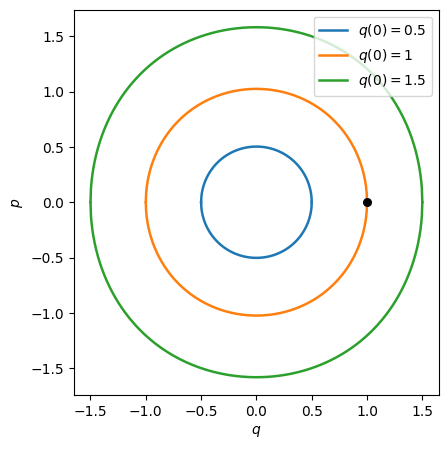

In [9]:
fig, ax = plt.subplots(figsize=(6.4,5.0))
for amplitude in [0.5, 1.0, 1.5]:
    energy = amplitude**2/2 + eps*amplitude**4/4
    q = np.linspace(-amplitude, amplitude, 700)
    p = np.sqrt(np.maximum(0, 2*energy - q*q - eps*q**4/2))
    line, = ax.plot(q, p, lw=1.8, label=fr'$q(0)={amplitude:g}$')
    ax.plot(q, -p, color=line.get_color(), lw=1.8)
ax.scatter([1.0], [0.0], c='black', s=30, zorder=3)
ax.set(xlabel='$q$', ylabel='$p$')
ax.set_aspect('equal', adjustable='box')
ax.legend(loc = 'upper right')
plt.show()


### 11.4.2 One correction iteration (for the Duffing oscillator)

We rescale time by the unknown frequency of the desired orbit as $\tau=\omega t$, so that the ODEs become

```{math}
:label: ch11-duffing-rescaled
\omega\frac{dq}{d\tau}=p,\qquad
\omega\frac{dp}{d\tau}=-q-\varepsilon q^3.
```

With this rescaling, we seek $2\pi$-periodic functions $q(\tau),p(\tau)$. (This will have a further advantage for numerical computation that we'll see later.) We start from the initial guesses

$$\omega_0=1,\qquad q_0(\tau)=\cos\tau,\qquad p_0(\tau)=-\sin\tau$$

that satisfy the initial conditions $q(0) = 1$, $p(0) = 0$. We make a small correction to each quantity,

$$\omega_1=\omega_0+\delta\omega,\qquad
q_1=q_0+\delta q,\qquad p_1=p_0+\delta p.$$

The corrections $\delta q,\delta p$ should also be $2\pi$ periodic, since the whole solution needs to be $2\pi$ periodic. Substitute these expressions into the nonlinear equations and drop all terms quadratic or higher in the corrections $\delta q,\delta p,\delta\omega$ to get

```{math}
:label: ch11-duffing-linearized
\omega_0\frac{d}{d\tau}
\begin{pmatrix}\delta q\\\delta p\end{pmatrix}
=
\begin{pmatrix}0&1\\-1-3\varepsilon\cos^2\tau&0\end{pmatrix}
\begin{pmatrix}\delta q\\\delta p\end{pmatrix}
+\delta\omega\begin{pmatrix}\sin\tau\\\cos\tau\end{pmatrix}
-\begin{pmatrix}0\\\varepsilon\cos^3\tau\end{pmatrix}.
```

Notice the factor $-3\varepsilon\cos^2\tau$ in the matrix. This wasn't present in the analytic, conventional Lindstedt--Poincaré correction at first order, it is clearly an order $\varepsilon$ different thant the rest of the terms. In the **numerical** iteration we retain it; doing so is one reason this numerical algorithm has quick(er) convergence.

Because our approximate orbit already satisfies $q_0(0)=1$ and $p_0(0)=0$, set $\delta q(0)=\delta p(0)=0$. 
The equation we obtained for the corrections $\delta q$ and $\delta p$ is a set of coupled linear, inhomogeneous ODEs, containing an unknown paramater $\delta \omega$. Its solution can be written in terms of this parameter as

$$\begin{pmatrix}\delta q(\tau)\\\delta p(\tau)\end{pmatrix}
=f_1(\tau)-\delta\omega\,f_2(\tau),$$

where $f_1,f_2$ both vanish at $\tau=0$, and are particular solutions of the ODE. Note that the homogeneous solution does not enter into $f_1$ or $f_2$ due to the zero initial condition, as we'll see later, due to the non-isolation of the orbits of the Duffing equation. 

To fix the $\delta \omega$ parameter, we need to minimize secural terms. One was to do that is to minimize the magnitude of the solution at $\tau = 2\pi$, i.e. make it as close to periodic as possible (in this case, we started from zero initial conditions). This constraint can be phrased as a scalar least-squares problem,

$$\min_{\delta\omega}\left\|f_1(2\pi)-\delta\omega f_2(2\pi)\right\|_2.$$

It has the solution (try it yourself: differentiate the expression with respect to $\delta \omega$, and set to zero)

```{math}
:label: ch11-domega
\delta\omega
=\frac{f_2(2\pi)^Tf_1(2\pi)}{f_2(2\pi)^Tf_2(2\pi)},
```

provided $f_2(2\pi)\ne0$. We then update the entire orbit and its frequency, and may repeat the step.


### 11.4.3 The general correction equation

The Duffing oscillator represents a special case of a more general problem.
If we denote the correction vector, $[ \delta q, \delta p]$, as $y$, then we know that the Duffing oscillator has $y(0) = 0$. This is not true in general, for isolated orbits, where the correction we need to make to our initial guess $x_0$ may not be zero at $\tau = 0$.
We also haven't explained how the correction equation may be written down and solved iteratively without symbolic algebra, which we do below.

For a general autonomous nonlinear system $\dot{x}=f(x)$, rescale time as before,

$$\omega x'(\tau)=f(x(\tau)), \qquad 0\leq\tau\leq 2\pi,$$

where a prime now denotes differentiation with respect to $\tau$. Let $x_0(\tau)$ be an initial, approximate $2\pi$-periodic orbit and $\omega_0$ its approximate frequency, which may not satisfy the ODE. In one step, let us make the corrections

$$x=x_0+y,\qquad \omega=\omega_0+\delta\omega.$$

After substitution back into the ODE and linearization in terms of corrections, the correction $y$ satisfies

```{math}
:label: ch11-correction
\omega_0 y'(\tau)=A(\tau)y(\tau)+r(\tau)-\delta\omega\,x_0'(\tau),
```

where

$$A(\tau)=\left.\frac{\partial f}{\partial x}\right|_{x=x_0(\tau)},\qquad
r(\tau)=f(x_0(\tau))-\omega_0x_0'(\tau).$$

The function $r$ is the **ODE residual** of our current approximation. If $r\equiv0$ and the orbit is periodic, there is nothing to correct since the solution satisfies the ODE, otherwise it is a measure of error.

Let $Y(\tau)$ be the fundamental (matrix) solution of $\omega_0Y'=AY$, with $Y(0)=I$, and denote the (approximate) monodromy matrix as $M=Y(2\pi)$. Define $f_1,f_2$ as the particular solutions that satisfy

\begin{align}
\omega_0 f_1'&=Af_1+r, &f_1(0)&=0,\\
\omega_0 f_2'&=Af_2+x_0', &f_2(0)&=0.
\end{align}

Then the general solution of the correction equation is

```{math}
:label: ch11-general-solution
 y(\tau)=Y(\tau)y(0)+f_1(\tau)-\delta\omega f_2(\tau).
```

We need to choose $y(0)$ and $\delta\omega$ so that $y(2\pi)=y(0)$, i.e. enforce periodicity and eliminate secular terms. This, if $x \in \mathbb{R}^d$, only provides $d$ constraints, whereas we have $d+1$ unknowns (the entries of $y(0)$, and the scalar $\delta \omega$). We complete the system with an additional constraint, a **phase condition** $f(x_0(0))^Ty(0)=0$. This excludes a correction along the direction of the orbit by requiring that the correction is orthogonal to the flow of the orbit, as any correction along the orbit would result in the same orbit. Together these give, for the general **isolated orbit**,

```{math}
:label: ch11-bordered-system
\begin{pmatrix}
I-M & f_2(2\pi)\\
f(x_0(0))^T & 0
\end{pmatrix}
\begin{pmatrix}y(0)\\\delta\omega\end{pmatrix}
=
\begin{pmatrix}f_1(2\pi)\\0\end{pmatrix}.
```

A caveat is that the system can be singular if the orbit sought is **degenerate**, or nearly singular if orbits exists close to one another. 

## 11.5 Fourier interpolation

### 11.5.1 Representing the whole periodic orbit

The algorithm needs a representation for several $2\pi$-periodic functions, e.g. $x_0$, so that we may evaluate them at any $\tau$. Fourier series are a natural choice, since the functions are periodic:

$$x_0(\tau)\approx\sum_{k=-m}^m a_k e^{ik\tau}.$$

On an odd number $n=2m+1$ of equispaced nodes $\tau_j=2\pi j/n$, the coefficients can be computed by the FFT. The derivative is obtained by multiplying each coefficient by $ik$:

$$x'_0(\tau)\approx\sum_{k=-m}^{m}ik\,a_k e^{ik\tau}.$$

The FFT costs $\mathcal{O}(n\log n)$ operations per component. If the orbit is analytic, its Fourier coefficients typically decay exponentially, so modest values of $n$ may suffice. Nonlinear products can produce higher modes, however, so $n$ must be large enough to control **aliasing**. 

```{admonition} Question
Why is Fourier interpolation a more natural representation here than a single high-degree polynomial on $[0,2\pi]$?
```


## 11.6 Isolated and non-isolated periodic orbits

There is an important distinction between the analytical result for the numerical algorithm and the Duffing example:

- For an **isolated periodic orbit**, the only unit Floquet multiplier is typically the trivial one corresponding to time translation. The phase condition fixes that freedom, and the linear system can be invertible. Under assumptions of smoothness for $f$ and nondegeneracy of the orbit, the numerical Lindstedt--Poincare iteration converges *quadratically* (compare with the slower, exponential convergence of a naive Runge--Kutta method).
- For a **non-isolated periodic orbit**, as in the Duffing equation, nearby energy levels supply a continuous family of available periodic orbits. This would make the linear system singular, but it is not necessary to solve: we *prescribe* an amplitude or energy, or add another appropriate constraint to select the orbit desired. Fixing $q(0)=1$, $p(0)=0$ (or, in summary, $y(0) = 0$) is the choice we used here.

This distinction also affects the monodromy matrix: for the Duffing equation, both eigenvalues are $1$. The family of orbits is therefore not asymptotically attracting. It is precisely the situation in which simply following a nearby trajectory will not lead to finding the desired orbit, so the naive Runge--Kutta approach would fail to converge.

```{admonition} Question
Suppose an algorithm produces a very small ODE residual for a periodic-looking trajectory, but its starting amplitude has drifted from $1$ to $0.9$. Has it necessarily found the orbit we requested?
```

No: a small residual means the computed function nearly satisfies the ODE, but an amplitude constraint is also needed to identify the **particular** member of a non-isolated family.
